In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
X = df[["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()
y = df["Survived"]

print("Пропуски до обработки:")
print(X.isnull().sum())

X.loc[:, "Age"] = X["Age"].fillna(X["Age"].median())
X.loc[:, "Sex"] = X["Sex"].map({"male": 0, "female": 1})

print("\nПропуски после обработки:")
print(X.isnull().sum())
print("\nТипы данных:")
print(X.dtypes)
print("Пропусков в X:", int(X.isnull().sum().sum()))

Пропуски до обработки:
Pclass      0
Age       177
Sex         0
Fare        0
SibSp       0
Parch       0
dtype: int64

Пропуски после обработки:
Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64

Типы данных:
Pclass      int64
Age       float64
Sex        object
Fare      float64
SibSp       int64
Parch       int64
dtype: object
Пропусков в X: 0


In [3]:
data_corr = X.copy()
data_corr["Survived"] = y

print("Столбцы таблицы:")
print(data_corr.columns.tolist())
print("\nПервые строки:")
display(data_corr.head())
print("\nТипы данных:")
print(data_corr.dtypes)
print("\nКоличество пропусков:")
print(data_corr.isnull().sum())

Столбцы таблицы:
['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']

Первые строки:


,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,0,7.2500,1,0,0
1,1,38.0,1,71.2833,1,0,1
2,3,26.0,1,7.9250,0,0,1
3,1,35.0,1,53.1000,1,0,1
4,3,35.0,0,8.0500,0,0,0



Типы данных:
Pclass        int64
Age         float64
Sex          object
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

Количество пропусков:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


In [4]:
corr_matrix = data_corr.corr(numeric_only=True).round(2)
print("Корреляционная матрица:")
display(corr_matrix)

survived_corr = corr_matrix["Survived"].drop("Survived")
positive_feature = survived_corr.idxmax()
negative_feature = survived_corr.idxmin()

print("Самая сильная положительная корреляция с Survived:")
print(positive_feature, survived_corr[positive_feature])
print("\nСамая сильная отрицательная корреляция с Survived:")
print(negative_feature, survived_corr[negative_feature])

Корреляционная матрица:


,Pclass,Age,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.34,-0.55,0.08,0.02,-0.34
Age,-0.34,1.00,0.10,-0.23,-0.17,-0.06
Fare,-0.55,0.10,1.00,0.16,0.22,0.26
SibSp,0.08,-0.23,0.16,1.00,0.41,-0.04
Parch,0.02,-0.17,0.22,0.41,1.00,0.08
Survived,-0.34,-0.06,0.26,-0.04,0.08,1.00


Самая сильная положительная корреляция с Survived:
Fare 0.26

Самая сильная отрицательная корреляция с Survived:
Pclass -0.34


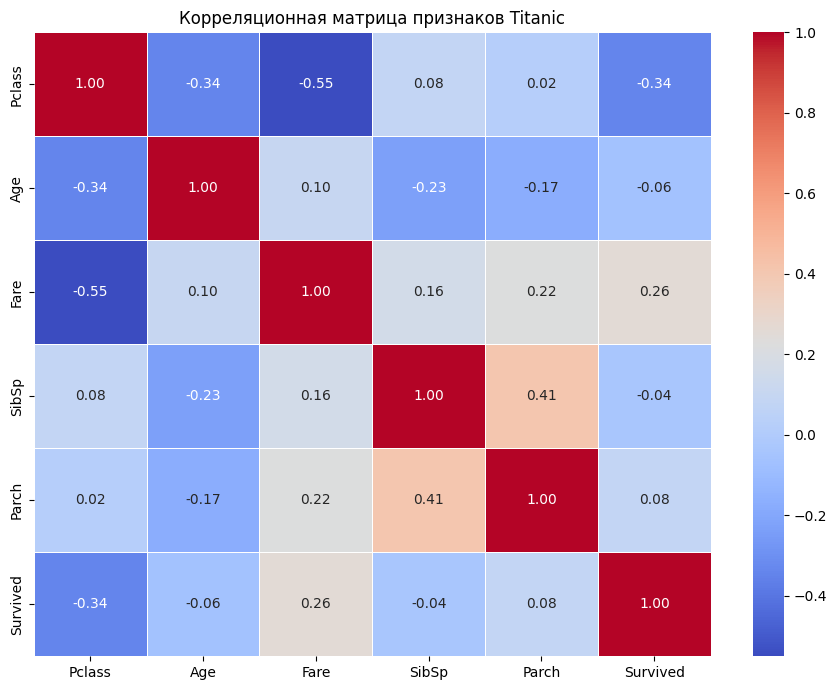

In [5]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Корреляционная матрица признаков Titanic")
plt.tight_layout()
plt.show()

In [6]:
print("Краткий вывод:")
print(f"Наиболее сильная положительная связь с Survived: {positive_feature} (r = {survived_corr[positive_feature]:.2f}).")
print(f"Наиболее сильная отрицательная связь с Survived: {negative_feature} (r = {survived_corr[negative_feature]:.2f}).")
print("Для предсказания могут быть полезны Pclass, Sex и Fare.")
print("Выбирать признаки только по корреляции нельзя: нужно проверять качество модели на тестовых данных.")
print("Корреляция не доказывает причинно-следственную связь.")

Краткий вывод:
Наиболее сильная положительная связь с Survived: Fare (r = 0.26).
Наиболее сильная отрицательная связь с Survived: Pclass (r = -0.34).
Для предсказания могут быть полезны Pclass, Sex и Fare.
Выбирать признаки только по корреляции нельзя: нужно проверять качество модели на тестовых данных.
Корреляция не доказывает причинно-следственную связь.
